# 1. 分析の目的

ホテル予約のキャンセルを予約登録直後に予測し、キャンセルの見逃しを減らすことを目的とする。

このNotebookでは、Random Forestを使って次の順に検証する。

1. 予約登録直後に利用できる特徴量へ限定する
2. 時系列を考慮してTrain・Validation・Final Testへ分割する
3. 過学習を抑えるハイパーパラメータをValidationで選ぶ
4. `country`追加前後を比較する
5. `agent`の上位10社・20社・30社を比較する
6. Validationでキャンセル判定閾値を選ぶ
7. 方針確定後にFinal Testで一度だけ評価する

モデルの選択と閾値調整にはTrainとValidationだけを使い、Final Testは最終確認にのみ使用する。


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import Markdown, display
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils.validation import check_is_fitted


sns.set_theme(style="whitegrid", context="notebook")
COLORS = {
    "primary": "#2F6690",
    "secondary": "#F28E2B",
    "accent": "#59A14F",
    "danger": "#E15759",
    "neutral": "#9D9D9D",
}
pd.set_option("display.max_columns", 50)

# notebooks/からの実行と、リポジトリ直下からの実行の両方に対応する
data_candidates = [
    Path("../data/hotel_bookings.csv"),
    Path("data/hotel_bookings.csv"),
]
DATA_PATH = next((path for path in data_candidates if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "hotel_bookings.csvが見つかりません。READMEの手順に従いdata/へ配置してください。"
    )


# 2. データの読み込み・前処理

予測時点を「予約登録直後」とする。目的変数が確定した後に得られる情報や、予約登録時点で利用可能か確認できない情報は除外する。

countryとagentは後の比較実験で追加するため、共通特徴量から一度外して管理する。欠損補完、上位カテゴリの選定、One-Hot EncodingはPipeline内で行う。


In [2]:
df = pd.read_csv(DATA_PATH)
df = df.rename(columns={" ": "hotel"})

TARGET = "is_canceled"
COUNTRY = "country"

POST_BOOKING_COLUMNS = [
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type",
    "booking_changes",
    "days_in_waiting_list",
]

# 予約登録時点の値である保証がないため保守的に除外する
UNCERTAIN_AT_REGISTRATION_COLUMNS = [
    "deposit_type",
    "adr",
    "total_of_special_requests",
]

NOT_USED_COLUMNS = ["agent", "company"]

excluded_columns = set(
    [TARGET, COUNTRY]
    + POST_BOOKING_COLUMNS
    + UNCERTAIN_AT_REGISTRATION_COLUMNS
    + NOT_USED_COLUMNS
)

baseline_feature_columns = [
    column for column in df.columns if column not in excluded_columns
]
country_feature_columns = baseline_feature_columns + [COUNTRY]
agent_feature_columns = country_feature_columns + ["agent"]

feature_policy = pd.DataFrame({
    "Category": [
        "Common features",
        "Added in country experiment",
        "Added in agent experiment",
        "Excluded after booking / target leakage risk",
        "Excluded conservatively",
        "Not used",
    ],
    "Columns": [
        ", ".join(baseline_feature_columns),
        COUNTRY,
        "agent",
        ", ".join(POST_BOOKING_COLUMNS),
        ", ".join(UNCERTAIN_AT_REGISTRATION_COLUMNS),
        "company",
    ],
})

print("データ件数・列数:", df.shape)
print("共通特徴量数:", len(baseline_feature_columns))
print("最終候補のraw特徴量数:", len(agent_feature_columns))
display(feature_policy)


データ件数・列数: (119390, 32)
共通特徴量数: 20
最終候補のraw特徴量数: 22


,Category,Columns
0,Common features,"hotel, lead_time, arrival_date_year, arrival_d..."
1,Added in country experiment,country
2,Added in agent experiment,agent
3,Excluded after booking / target leakage risk,"reservation_status, reservation_status_date, a..."
4,Excluded conservatively,"deposit_type, adr, total_of_special_requests"
5,Not used,company


In [3]:
class TopCountryGrouper(BaseEstimator, TransformerMixin):
    """fitしたデータの上位Nか国を残し、それ以外をOtherへまとめる。"""

    def __init__(self, top_n=17):
        self.top_n = top_n

    @staticmethod
    def _to_series(X):
        if isinstance(X, pd.DataFrame):
            values = X.iloc[:, 0].copy()
        else:
            values = pd.Series(np.asarray(X).reshape(-1))
        return values.fillna("Unknown").astype(str)

    def fit(self, X, y=None):
        values = self._to_series(X)
        self.top_countries_ = (
            values[values != "Unknown"]
            .value_counts()
            .head(self.top_n)
            .index
            .tolist()
        )
        return self

    def transform(self, X):
        check_is_fitted(self, "top_countries_")
        values = self._to_series(X)
        grouped = values.where(
            values.isin(self.top_countries_) | values.eq("Unknown"),
            "Other",
        )
        return grouped.to_numpy().reshape(-1, 1)

    def get_feature_names_out(self, input_features=None):
        return np.array(["country"], dtype=object)


class TopAgentGrouper(BaseEstimator, TransformerMixin):
    """fitしたデータの上位N代理店を残し、それ以外をOtherへまとめる。"""

    def __init__(self, top_n=10):
        self.top_n = top_n

    @staticmethod
    def _normalize_value(value):
        if pd.isna(value):
            return "Unknown"

        # 9.0と9を同じカテゴリ"9"として扱う
        if isinstance(value, (int, float, np.integer, np.floating)):
            numeric_value = float(value)
            if np.isfinite(numeric_value) and numeric_value.is_integer():
                return str(int(numeric_value))
            return format(numeric_value, "g")

        return str(value).strip()

    @classmethod
    def _to_series(cls, X):
        if isinstance(X, pd.DataFrame):
            values = X.iloc[:, 0].copy()
        else:
            values = pd.Series(np.asarray(X).reshape(-1))
        return values.map(cls._normalize_value)

    def fit(self, X, y=None):
        values = self._to_series(X)
        self.top_agents_ = (
            values[values != "Unknown"]
            .value_counts()
            .head(self.top_n)
            .index
            .tolist()
        )
        return self

    def transform(self, X):
        check_is_fitted(self, "top_agents_")
        values = self._to_series(X)
        grouped = values.where(
            values.isin(self.top_agents_) | values.eq("Unknown"),
            "Other",
        )
        return grouped.to_numpy().reshape(-1, 1)

    def get_feature_names_out(self, input_features=None):
        return np.array(["agent"], dtype=object)


# 3. データリーク対策・データ分割

予約登録日そのものがないため、到着日からlead_timeを引いて推定予約日を作る。推定予約日の古い順に、Train 60%・Validation 20%・Final Test 20%へ分割する。

予約IDがないため、完全一致レコードを同じ予約と断定して削除することはできない。そこでレコードは残し、目的変数と事後ステータスを除いた列から重複グループを作り、分割をまたいでいないことだけを確認する。


In [4]:
arrival_month_number = pd.to_datetime(
    df["arrival_date_month"], format="%B"
).dt.month
arrival_date = pd.to_datetime({
    "year": df["arrival_date_year"],
    "month": arrival_month_number,
    "day": df["arrival_date_day_of_month"],
})
estimated_booking_date = arrival_date - pd.to_timedelta(df["lead_time"], unit="D")

train_cutoff = estimated_booking_date.quantile(0.60, interpolation="lower")
validation_cutoff = estimated_booking_date.quantile(0.80, interpolation="lower")

train_index = df.index[estimated_booking_date <= train_cutoff]
validation_index = df.index[
    (estimated_booking_date > train_cutoff)
    & (estimated_booking_date <= validation_cutoff)
]
final_test_index = df.index[estimated_booking_date > validation_cutoff]

duplicate_group_columns = [
    column
    for column in df.columns
    if column not in [TARGET, "reservation_status", "reservation_status_date"]
]
duplicate_group_id = pd.util.hash_pandas_object(
    df[duplicate_group_columns], index=False
)
train_groups = set(duplicate_group_id.loc[train_index])
validation_groups = set(duplicate_group_id.loc[validation_index])
final_test_groups = set(duplicate_group_id.loc[final_test_index])

assert train_groups.isdisjoint(validation_groups)
assert train_groups.isdisjoint(final_test_groups)
assert validation_groups.isdisjoint(final_test_groups)

split_summary = pd.DataFrame({
    "Rows": [len(train_index), len(validation_index), len(final_test_index)],
    "Start": [
        estimated_booking_date.loc[train_index].min(),
        estimated_booking_date.loc[validation_index].min(),
        estimated_booking_date.loc[final_test_index].min(),
    ],
    "End": [
        estimated_booking_date.loc[train_index].max(),
        estimated_booking_date.loc[validation_index].max(),
        estimated_booking_date.loc[final_test_index].max(),
    ],
    # Final Testの目的変数分布はモデル・閾値確定前に見ない
    "Cancellation_Rate": [
        df.loc[train_index, TARGET].mean(),
        df.loc[validation_index, TARGET].mean(),
        np.nan,
    ],
}, index=["Train", "Validation", "Final Test"])

display(split_summary.style.format({"Cancellation_Rate": "{:.1%}"}))
print("完全重複行数:", int(df.duplicated().sum()))
print("重複グループの分割またぎ: 0")


,Rows,Start,End,Cancellation_Rate
Train,71688,2013-06-24 00:00:00,2016-08-17 00:00:00,38.8%
Validation,23999,2016-08-18 00:00:00,2017-01-12 00:00:00,37.3%
Final Test,23703,2017-01-13 00:00:00,2017-08-31 00:00:00,nan%


完全重複行数: 31994
重複グループの分割またぎ: 0


In [5]:
# 数値・カテゴリ列はTrainの型情報だけから確定する
train_baseline_data = df.loc[train_index, baseline_feature_columns]
numeric_columns = train_baseline_data.select_dtypes(include=["number"]).columns.tolist()
categorical_columns = train_baseline_data.select_dtypes(exclude=["number"]).columns.tolist()


def build_random_forest_pipeline(
    include_country,
    agent_top_n,
    model_params,
):
    """既存の前処理条件を共通化したRandom Forest Pipelineを作る。"""

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    transformers = [
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ]

    if include_country:
        country_pipeline = Pipeline([
            ("group", TopCountryGrouper(top_n=17)),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ])
        transformers.append(("country", country_pipeline, [COUNTRY]))

    if agent_top_n is not None:
        agent_pipeline = Pipeline([
            ("group", TopAgentGrouper(top_n=agent_top_n)),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ])
        transformers.append(("agent", agent_pipeline, ["agent"]))

    preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

    return Pipeline([
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(**model_params)),
    ])


def calculate_metrics(y_true, y_pred, y_probability):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_probability),
        "PR-AUC": average_precision_score(y_true, y_probability),
    }


# 4. Random Forestの学習と改善

まずcountryとagentを含まない共通特徴量で、過学習を抑える設定をValidationで比較する。木の本数と乱数条件は固定し、`max_depth`、`min_samples_leaf`、`min_samples_split`だけを既存候補の範囲で比較する。


In [6]:
COMMON_RF_PARAMS = {
    "n_estimators": 200,
    "random_state": 42,
    "n_jobs": -1,
}

regularization_candidates = {
    "default_reference": {
        "max_depth": None,
        "min_samples_leaf": 1,
        "min_samples_split": 2,
    },
    "depth24_leaf2": {
        "max_depth": 24,
        "min_samples_leaf": 2,
        "min_samples_split": 5,
    },
    "depth18_leaf4": {
        "max_depth": 18,
        "min_samples_leaf": 4,
        "min_samples_split": 8,
    },
    "depth12_leaf8": {
        "max_depth": 12,
        "min_samples_leaf": 8,
        "min_samples_split": 16,
    },
}

X_train_baseline = df.loc[train_index, baseline_feature_columns]
y_train = df.loc[train_index, TARGET]
X_validation_baseline = df.loc[validation_index, baseline_feature_columns]
y_validation = df.loc[validation_index, TARGET]

candidate_models = {}
regularization_rows = []

for candidate_name, candidate_params in regularization_candidates.items():
    model_params = {**COMMON_RF_PARAMS, **candidate_params}
    model = build_random_forest_pipeline(
        include_country=False,
        agent_top_n=None,
        model_params=model_params,
    )
    model.fit(X_train_baseline, y_train)
    candidate_models[candidate_name] = model

    train_probability = model.predict_proba(X_train_baseline)[:, 1]
    validation_probability = model.predict_proba(X_validation_baseline)[:, 1]
    train_auc = roc_auc_score(y_train, train_probability)
    validation_auc = roc_auc_score(y_validation, validation_probability)

    regularization_rows.append({
        "Candidate": candidate_name,
        **candidate_params,
        "Train_ROC_AUC": train_auc,
        "Validation_ROC_AUC": validation_auc,
        "ROC_AUC_Gap": train_auc - validation_auc,
    })

regularization_comparison = (
    pd.DataFrame(regularization_rows).set_index("Candidate")
)
display(regularization_comparison.round(4))

# Validation ROC-AUCが最も高い既存候補を採用する
selected_candidate = regularization_comparison["Validation_ROC_AUC"].idxmax()
selected_model_params = {
    **COMMON_RF_PARAMS,
    **regularization_candidates[selected_candidate],
}
baseline_validation_model = candidate_models[selected_candidate]

print("選択した候補:", selected_candidate)
print("選択したパラメータ:", selected_model_params)


,max_depth,min_samples_leaf,min_samples_split,Train_ROC_AUC,Validation_ROC_AUC,ROC_AUC_Gap
Candidate,,,,,,
default_reference,NaN,1,2,0.9965,0.7719,0.2245
depth24_leaf2,24.0,2,5,0.9656,0.7920,0.1736
depth18_leaf4,18.0,4,8,0.9321,0.7930,0.1392
depth12_leaf8,12.0,8,16,0.8951,0.7883,0.1068


選択した候補: depth18_leaf4
選択したパラメータ: {'n_estimators': 200, 'random_state': 42, 'n_jobs': -1, 'max_depth': 18, 'min_samples_leaf': 4, 'min_samples_split': 8}


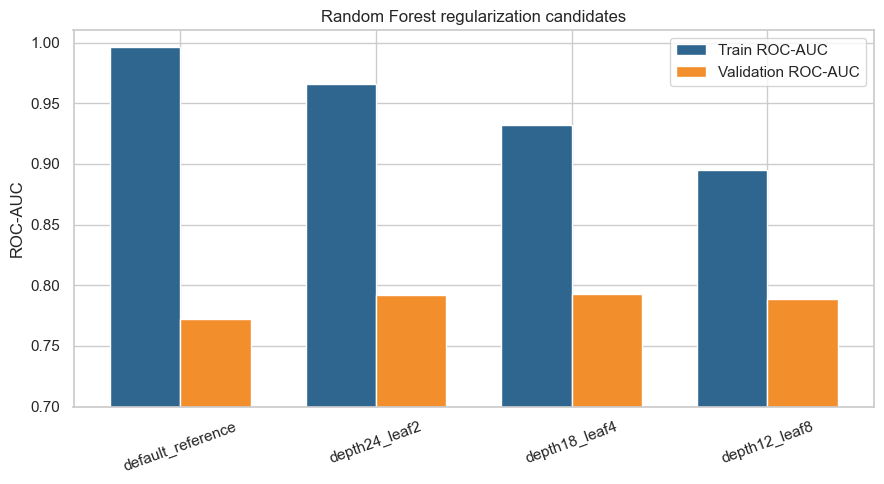

In [7]:
plt.figure(figsize=(9, 5))
x = np.arange(len(regularization_comparison))
width = 0.36
plt.bar(
    x - width / 2,
    regularization_comparison["Train_ROC_AUC"],
    width,
    label="Train ROC-AUC",
    color=COLORS["primary"],
)
plt.bar(
    x + width / 2,
    regularization_comparison["Validation_ROC_AUC"],
    width,
    label="Validation ROC-AUC",
    color=COLORS["secondary"],
)
plt.xticks(x, regularization_comparison.index, rotation=20)
plt.ylabel("ROC-AUC")
plt.ylim(0.70, 1.01)
plt.title("Random Forest regularization candidates")
plt.legend()
plt.tight_layout()
plt.show()


In [8]:
selected_candidate_row = regularization_comparison.loc[selected_candidate]
default_candidate_row = regularization_comparison.loc["default_reference"]

display(Markdown(f"""
### 改善結果

Validation ROC-AUCが最も高かった`{selected_candidate}`を採用した。Validation ROC-AUCは **{selected_candidate_row['Validation_ROC_AUC']:.4f}**、Trainとの差は **{selected_candidate_row['ROC_AUC_Gap']:.4f}** だった。

無制限に近い`default_reference`はTrain ROC-AUCが **{default_candidate_row['Train_ROC_AUC']:.4f}** まで上がる一方、Validationとの差が **{default_candidate_row['ROC_AUC_Gap']:.4f}** あり、過学習が強かった。そこで、以降は深さと葉の最小件数を制限した同じ設定を使用する。
"""))



### 改善結果

Validation ROC-AUCが最も高かった`depth18_leaf4`を採用した。Validation ROC-AUCは **0.7930**、Trainとの差は **0.1392** だった。

無制限に近い`default_reference`はTrain ROC-AUCが **0.9965** まで上がる一方、Validationとの差が **0.2245** あり、過学習が強かった。そこで、以降は深さと葉の最小件数を制限した同じ設定を使用する。


### 過学習への対応

初期モデルでは、学習データと検証データの性能に差が見られたため、過学習の可能性を考えた。

そこで、Random Forestの `max_depth` と `min_samples_leaf` を調整し、モデルの複雑さを抑えることにした。

複数の設定を比較し、Validationの性能とTrainとの差を確認したうえで、最終的に `max_depth=18`、`min_samples_leaf=4` を採用した。

# 5. countryの追加による性能比較

共通特徴量だけのモデルと、`country`を追加したモデルを同じTrain・Validation、同じRandom Forest設定で比較する。

countryはPipelineのfit対象データで件数上位17か国を選び、それ以外を`Other`、欠損を`Unknown`としてOne-Hot Encodingする。Validationの国分布はカテゴリ選定に使わない。


In [9]:
X_train_country = df.loc[train_index, country_feature_columns]
X_validation_country = df.loc[validation_index, country_feature_columns]

country_validation_model = build_random_forest_pipeline(
    include_country=True,
    agent_top_n=None,
    model_params=selected_model_params,
)
country_validation_model.fit(X_train_country, y_train)

country_comparison_rows = []
for model_name, model, X_train_part, X_validation_part in [
    (
        "Random Forest (before country)",
        baseline_validation_model,
        X_train_baseline,
        X_validation_baseline,
    ),
    (
        "Random Forest (+ country)",
        country_validation_model,
        X_train_country,
        X_validation_country,
    ),
]:
    validation_prediction = model.predict(X_validation_part)
    validation_probability = model.predict_proba(X_validation_part)[:, 1]
    row = {"Model": model_name}
    row.update(
        calculate_metrics(
            y_validation,
            validation_prediction,
            validation_probability,
        )
    )
    country_comparison_rows.append(row)

country_validation_comparison = (
    pd.DataFrame(country_comparison_rows).set_index("Model")
)
country_difference = (
    country_validation_comparison.loc["Random Forest (+ country)"]
    - country_validation_comparison.loc["Random Forest (before country)"]
)
country_validation_comparison.loc["Difference"] = country_difference
display(country_validation_comparison.round(4))

fitted_country_grouper = (
    country_validation_model.named_steps["preprocess"]
    .named_transformers_["country"]
    .named_steps["group"]
)
print("Trainから選ばれた上位17か国:")
print(fitted_country_grouper.top_countries_)


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Model,,,,,,
Random Forest (before country),0.7344,0.6741,0.5567,0.6098,0.793,0.7249
Random Forest (+ country),0.7696,0.7841,0.5269,0.6303,0.860,0.7962
Difference,0.0352,0.1100,-0.0297,0.0205,0.067,0.0713


Trainから選ばれた上位17か国:
['PRT', 'GBR', 'FRA', 'ESP', 'DEU', 'ITA', 'IRL', 'BEL', 'NLD', 'BRA', 'USA', 'CHE', 'AUT', 'CN', 'SWE', 'POL', 'CHN']


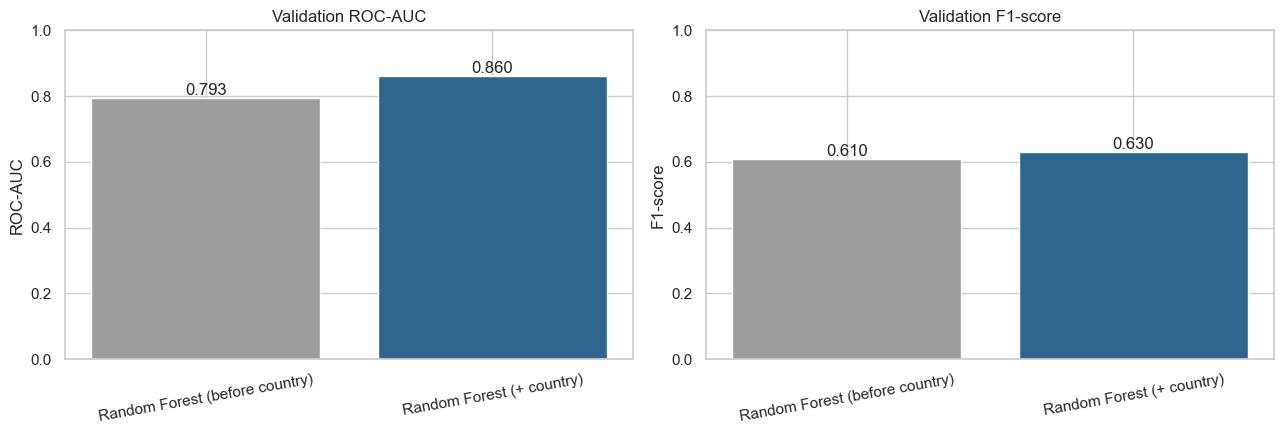


country追加後はValidation ROC-AUCが **0.7930** から **0.8600**、F1-scoreが **0.6098** から **0.6303** へ上がった。一方、Recallは低下したため、後の閾値調整で見逃しとのバランスを検討する。


In [10]:
country_plot = country_validation_comparison.drop(index="Difference")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for axis, metric in zip(axes, ["ROC-AUC", "F1-score"]):
    bars = axis.bar(
        country_plot.index,
        country_plot[metric],
        color=[COLORS["neutral"], COLORS["primary"]],
    )
    axis.bar_label(bars, fmt="%.3f")
    axis.set_ylim(0, 1)
    axis.set_ylabel(metric)
    axis.set_title(f"Validation {metric}")
    axis.tick_params(axis="x", rotation=10)

plt.tight_layout()
plt.show()

display(Markdown(f"""
country追加後はValidation ROC-AUCが **{country_plot.loc['Random Forest (before country)', 'ROC-AUC']:.4f}** から **{country_plot.loc['Random Forest (+ country)', 'ROC-AUC']:.4f}**、F1-scoreが **{country_plot.loc['Random Forest (before country)', 'F1-score']:.4f}** から **{country_plot.loc['Random Forest (+ country)', 'F1-score']:.4f}** へ上がった。一方、Recallは低下したため、後の閾値調整で見逃しとのバランスを検討する。
"""))


# 6. agentの分類方法による性能比較

`agent`は数値の大小に意味がないカテゴリ変数として扱う。Trainの予約件数上位10社・20社・30社を個別カテゴリとして残し、それ以外を`Other`、欠損を`Unknown`とする。

country追加済みモデルをModel 0とし、Random Forestの設定や共通特徴量は変えずに4モデルを比較する。


,Retained_Agents,Covered_Reservations,Coverage_All_Train,Coverage_Known_Agent
Pattern,,,,
Top 10,10,"41,821",58.3%,66.5%
Top 20,20,"48,266",67.3%,76.7%
Top 30,30,"52,037",72.6%,82.7%


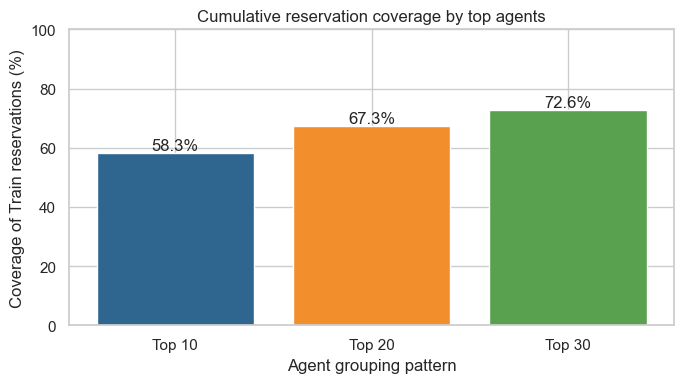

In [11]:
normalized_train_agent = TopAgentGrouper._to_series(
    df.loc[train_index, ["agent"]]
)
known_train_agent = normalized_train_agent[normalized_train_agent != "Unknown"]
train_agent_counts = known_train_agent.value_counts()

agent_coverage_rows = []
for top_n in [10, 20, 30]:
    covered_reservations = int(train_agent_counts.head(top_n).sum())
    agent_coverage_rows.append({
        "Pattern": f"Top {top_n}",
        "Retained_Agents": min(top_n, len(train_agent_counts)),
        "Covered_Reservations": covered_reservations,
        "Coverage_All_Train": covered_reservations / len(train_index),
        "Coverage_Known_Agent": covered_reservations / len(known_train_agent),
    })

agent_coverage = pd.DataFrame(agent_coverage_rows).set_index("Pattern")
display(agent_coverage.style.format({
    "Covered_Reservations": "{:,.0f}",
    "Coverage_All_Train": "{:.1%}",
    "Coverage_Known_Agent": "{:.1%}",
}))

plt.figure(figsize=(7, 4))
coverage_percent = agent_coverage["Coverage_All_Train"] * 100
bars = plt.bar(
    agent_coverage.index,
    coverage_percent,
    color=[COLORS["primary"], COLORS["secondary"], COLORS["accent"]],
)
plt.bar_label(bars, fmt="%.1f%%")
plt.ylabel("Coverage of Train reservations (%)")
plt.xlabel("Agent grouping pattern")
plt.title("Cumulative reservation coverage by top agents")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


In [12]:
agent_model_configs = {
    "Model 0: Country only": None,
    "Model A: Agent Top 10": 10,
    "Model B: Agent Top 20": 20,
    "Model C: Agent Top 30": 30,
}

X_train_agent = df.loc[train_index, agent_feature_columns]
X_validation_agent = df.loc[validation_index, agent_feature_columns]

agent_models = {
    "Model 0: Country only": country_validation_model,
}
agent_metric_rows = []
agent_validation_probabilities = {}

for model_name, top_n in agent_model_configs.items():
    if top_n is None:
        model = country_validation_model
        X_train_part = X_train_country
        X_validation_part = X_validation_country
    else:
        model = build_random_forest_pipeline(
            include_country=True,
            agent_top_n=top_n,
            model_params=selected_model_params,
        )
        model.fit(X_train_agent, y_train)
        agent_models[model_name] = model
        X_train_part = X_train_agent
        X_validation_part = X_validation_agent

    for dataset_name, X_part, y_part in [
        ("Train", X_train_part, y_train),
        ("Validation", X_validation_part, y_validation),
    ]:
        prediction = model.predict(X_part)
        probability = model.predict_proba(X_part)[:, 1]
        row = {"Model": model_name, "Dataset": dataset_name}
        row.update(calculate_metrics(y_part, prediction, probability))
        agent_metric_rows.append(row)

        if dataset_name == "Validation":
            agent_validation_probabilities[model_name] = probability

agent_all_metrics = pd.DataFrame(agent_metric_rows).set_index(["Model", "Dataset"])
agent_validation_comparison = agent_all_metrics.xs("Validation", level="Dataset")
display(agent_validation_comparison.round(4))

agent_pairwise_differences = pd.DataFrame({
    "Agent10 - Model0": (
        agent_validation_comparison.loc["Model A: Agent Top 10"]
        - agent_validation_comparison.loc["Model 0: Country only"]
    ),
    "Agent20 - Agent10": (
        agent_validation_comparison.loc["Model B: Agent Top 20"]
        - agent_validation_comparison.loc["Model A: Agent Top 10"]
    ),
    "Agent30 - Agent20": (
        agent_validation_comparison.loc["Model C: Agent Top 30"]
        - agent_validation_comparison.loc["Model B: Agent Top 20"]
    ),
}).T
display(agent_pairwise_differences.round(4))

agent_overfitting_rows = []
for model_name in agent_model_configs:
    train_metrics = agent_all_metrics.loc[(model_name, "Train")]
    validation_metrics = agent_all_metrics.loc[(model_name, "Validation")]
    agent_overfitting_rows.append({
        "Model": model_name,
        "Train_ROC_AUC": train_metrics["ROC-AUC"],
        "Validation_ROC_AUC": validation_metrics["ROC-AUC"],
        "ROC_AUC_Gap": train_metrics["ROC-AUC"] - validation_metrics["ROC-AUC"],
        "Train_F1": train_metrics["F1-score"],
        "Validation_F1": validation_metrics["F1-score"],
        "F1_Gap": train_metrics["F1-score"] - validation_metrics["F1-score"],
    })

agent_overfitting_comparison = (
    pd.DataFrame(agent_overfitting_rows).set_index("Model")
)
display(agent_overfitting_comparison.round(4))

# 最高ROC-AUCから0.001以内なら、よりカテゴリ数が少ないモデルを優先する
best_agent_validation_auc = agent_validation_comparison["ROC-AUC"].max()
simple_candidates = [
    model_name
    for model_name in agent_model_configs
    if agent_validation_comparison.loc[model_name, "ROC-AUC"]
    >= best_agent_validation_auc - 0.001
]
selected_agent_model_name = simple_candidates[0]
selected_agent_top_n = agent_model_configs[selected_agent_model_name]
selected_agent_model = agent_models[selected_agent_model_name]

print("Validationで選択したモデル:", selected_agent_model_name)
print("Final Testはこの選択に使用していません。")


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Model,,,,,,
Model 0: Country only,0.7696,0.7841,0.5269,0.6303,0.8600,0.7962
Model A: Agent Top 10,0.7839,0.7398,0.6482,0.6910,0.8804,0.8160
Model B: Agent Top 20,0.7819,0.7510,0.6209,0.6798,0.8810,0.8174
Model C: Agent Top 30,0.7798,0.7283,0.6529,0.6886,0.8777,0.8125


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Agent10 - Model0,0.0143,-0.0443,0.1213,0.0607,0.0204,0.0198
Agent20 - Agent10,-0.0019,0.0112,-0.0273,-0.0112,0.0006,0.0014
Agent30 - Agent20,-0.0021,-0.0227,0.0320,0.0088,-0.0033,-0.0049


,Train_ROC_AUC,Validation_ROC_AUC,ROC_AUC_Gap,Train_F1,Validation_F1,F1_Gap
Model,,,,,,
Model 0: Country only,0.9619,0.8600,0.1019,0.8257,0.6303,0.1954
Model A: Agent Top 10,0.9659,0.8804,0.0855,0.8513,0.6910,0.1603
Model B: Agent Top 20,0.9661,0.8810,0.0851,0.8501,0.6798,0.1703
Model C: Agent Top 30,0.9639,0.8777,0.0862,0.8376,0.6886,0.1490


Validationで選択したモデル: Model A: Agent Top 10
Final Testはこの選択に使用していません。


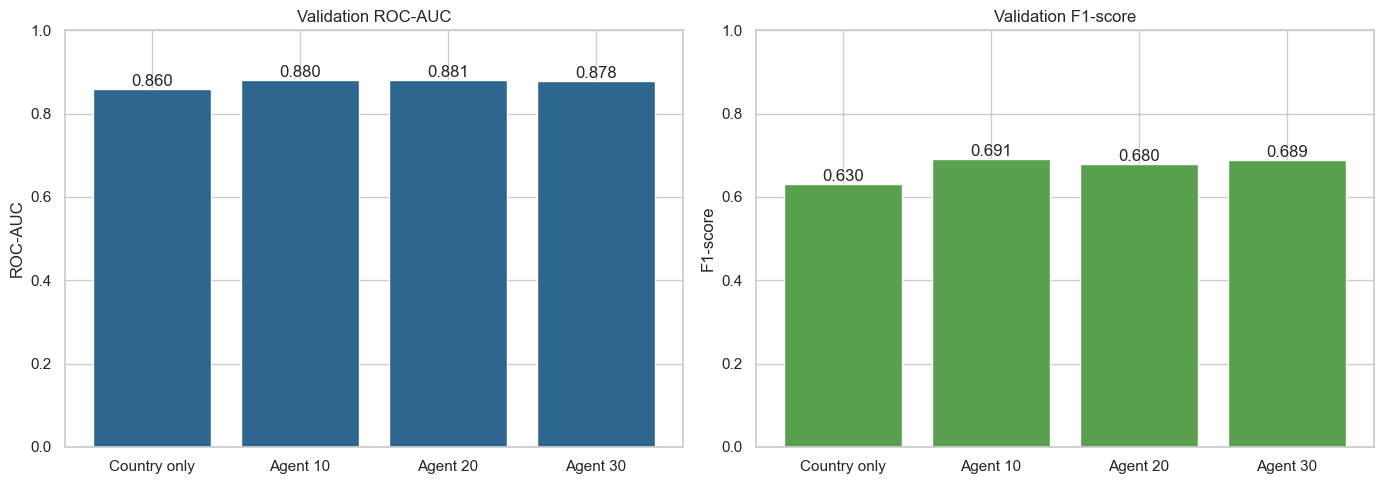

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
short_labels = ["Country only", "Agent 10", "Agent 20", "Agent 30"]

for axis, metric, color in [
    (axes[0], "ROC-AUC", COLORS["primary"]),
    (axes[1], "F1-score", COLORS["accent"]),
]:
    values = agent_validation_comparison[metric].to_numpy()
    bars = axis.bar(short_labels, values, color=color)
    axis.bar_label(bars, fmt="%.3f")
    axis.set_ylim(0, 1)
    axis.set_ylabel(metric)
    axis.set_title(f"Validation {metric}")

plt.tight_layout()
plt.show()


In [14]:
selected_agent_validation = agent_validation_comparison.loc[selected_agent_model_name]
best_agent_model_name = agent_validation_comparison["ROC-AUC"].idxmax()

display(Markdown(f"""
### agent分類方法の結論

Validation ROC-AUCの最高値は`{best_agent_model_name}`の **{best_agent_validation_auc:.4f}** だった。上位10社モデルは **{selected_agent_validation['ROC-AUC']:.4f}** で差が0.001以内であり、F1-scoreは **{selected_agent_validation['F1-score']:.4f}** と4モデル中で最も高かった。

そのため、カテゴリ数が少なく、性能差も小さい **agent上位10社モデル** を採用する。Final Testはこの判断に使用していない。
"""))



### agent分類方法の結論

Validation ROC-AUCの最高値は`Model B: Agent Top 20`の **0.8810** だった。上位10社モデルは **0.8804** で差が0.001以内であり、F1-scoreは **0.6910** と4モデル中で最も高かった。

そのため、カテゴリ数が少なく、性能差も小さい **agent上位10社モデル** を採用する。Final Testはこの判断に使用していない。


# 7. キャンセル判定閾値の調整

選択したcountry＋agent上位10社モデルについて、Validationの`predict_proba()`を使い、閾値0.20〜0.70を0.05刻みで比較する。

今回の目的はキャンセルの見逃しを減らしながらPrecisionとのバランスを取ることであるため、主な選択基準をF1-scoreとする。Recall 70%以上の中でPrecisionが最大となる閾値も、運用上の比較候補として残す。


In [15]:
validation_cancel_probability = agent_validation_probabilities[
    selected_agent_model_name
]

threshold_values = np.round(np.arange(0.20, 0.701, 0.05), 2)
threshold_rows = []

for threshold in threshold_values:
    threshold_prediction = (
        validation_cancel_probability >= threshold
    ).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_validation, threshold_prediction),
        "Precision": precision_score(
            y_validation, threshold_prediction, zero_division=0
        ),
        "Recall": recall_score(
            y_validation, threshold_prediction, zero_division=0
        ),
        "F1-score": f1_score(
            y_validation, threshold_prediction, zero_division=0
        ),
    })

threshold_comparison = pd.DataFrame(threshold_rows).set_index("Threshold")

f1_best_threshold = float(threshold_comparison["F1-score"].idxmax())
recall70_candidates = threshold_comparison[
    threshold_comparison["Recall"] >= 0.70
]
recall70_best_threshold = float(
    recall70_candidates
    .reset_index()
    .sort_values(["Precision", "Threshold"], ascending=[False, False])
    .iloc[0]["Threshold"]
)

# Notebook全体で使用する最終閾値をValidationのF1最大値に統一する
FINAL_THRESHOLD = f1_best_threshold

display(threshold_comparison.round(4))

threshold_candidates = pd.DataFrame({
    "Default 0.50": threshold_comparison.loc[0.50],
    "Maximum F1": threshold_comparison.loc[f1_best_threshold],
    "Recall >= 70%, maximum Precision": threshold_comparison.loc[
        recall70_best_threshold
    ],
}).T
threshold_candidates.insert(
    0,
    "Threshold",
    [0.50, f1_best_threshold, recall70_best_threshold],
)
display(threshold_candidates.round(4))

print(f"F1-score最大の閾値: {f1_best_threshold:.2f}")
print(f"Recall 70%以上でPrecision最大の閾値: {recall70_best_threshold:.2f}")
print(f"最終採用する閾値: {FINAL_THRESHOLD:.2f}")
print("Final Testは閾値選択に使用していません。")


,Accuracy,Precision,Recall,F1-score
Threshold,,,,
0.20,0.7103,0.5651,0.9676,0.7135
0.25,0.7463,0.6009,0.9512,0.7365
0.30,0.7651,0.6233,0.9344,0.7478
0.35,0.7687,0.6361,0.8872,0.7409
0.40,0.7766,0.6586,0.8320,0.7352
0.45,0.7817,0.6850,0.7673,0.7238
0.50,0.7839,0.7398,0.6482,0.6910
0.55,0.7737,0.8055,0.5180,0.6305
0.60,0.7542,0.8848,0.3916,0.5429


,Threshold,Accuracy,Precision,Recall,F1-score
Default 0.50,0.50,0.7839,0.7398,0.6482,0.6910
Maximum F1,0.30,0.7651,0.6233,0.9344,0.7478
"Recall >= 70%, maximum Precision",0.45,0.7817,0.6850,0.7673,0.7238


F1-score最大の閾値: 0.30
Recall 70%以上でPrecision最大の閾値: 0.45
最終採用する閾値: 0.30
Final Testは閾値選択に使用していません。


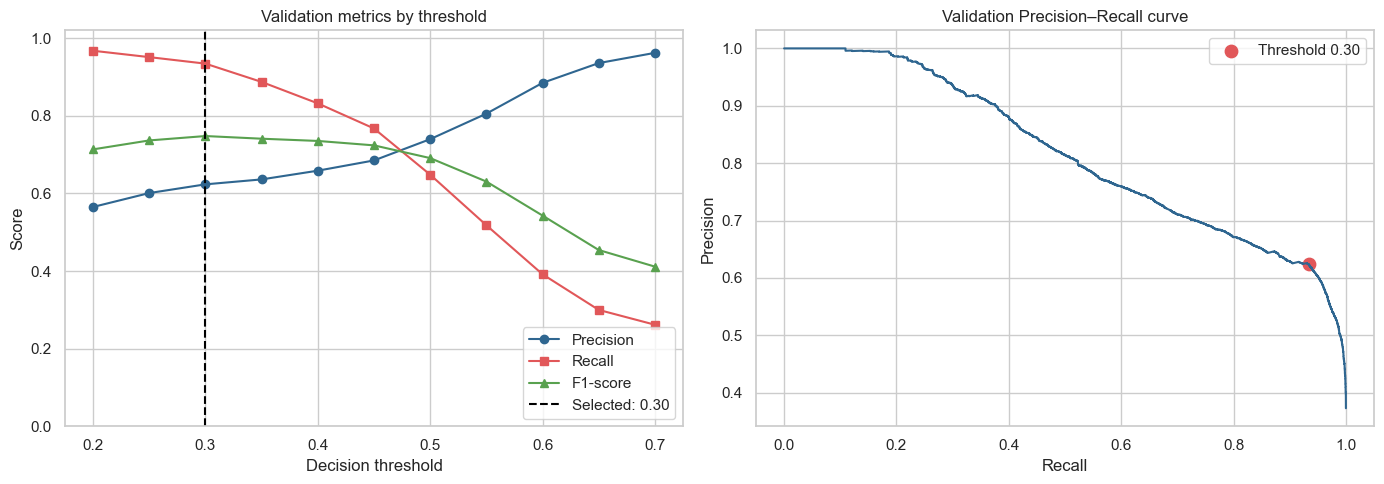

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for metric, marker, color in [
    ("Precision", "o", COLORS["primary"]),
    ("Recall", "s", COLORS["danger"]),
    ("F1-score", "^", COLORS["accent"]),
]:
    axes[0].plot(
        threshold_comparison.index,
        threshold_comparison[metric],
        marker=marker,
        color=color,
        label=metric,
    )
axes[0].axvline(
    FINAL_THRESHOLD,
    color="black",
    linestyle="--",
    label=f"Selected: {FINAL_THRESHOLD:.2f}",
)
axes[0].set_xlabel("Decision threshold")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.02)
axes[0].set_title("Validation metrics by threshold")
axes[0].legend()

curve_precision, curve_recall, _ = precision_recall_curve(
    y_validation,
    validation_cancel_probability,
)
axes[1].plot(curve_recall, curve_precision, color=COLORS["primary"])
axes[1].scatter(
    threshold_comparison.loc[FINAL_THRESHOLD, "Recall"],
    threshold_comparison.loc[FINAL_THRESHOLD, "Precision"],
    color=COLORS["danger"],
    s=80,
    label=f"Threshold {FINAL_THRESHOLD:.2f}",
)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Validation Precision–Recall curve")
axes[1].legend()

plt.tight_layout()
plt.show()


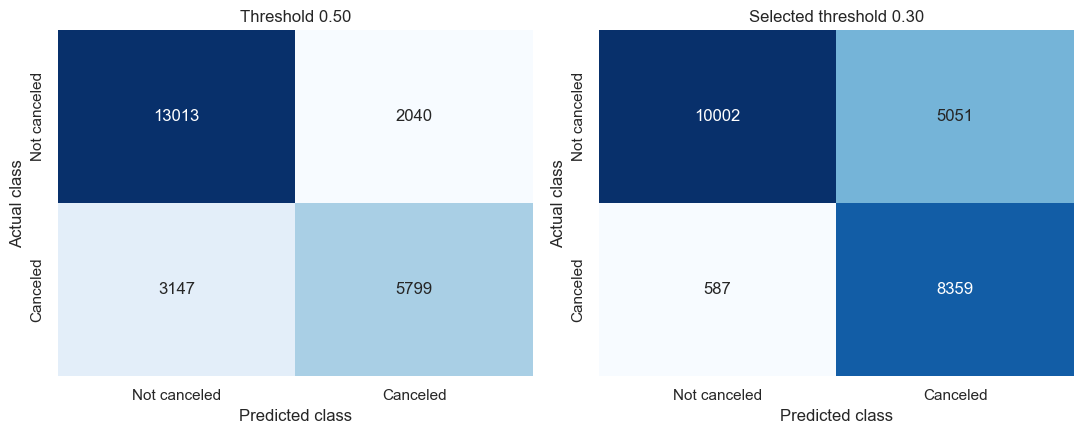

In [17]:
default_prediction = (validation_cancel_probability >= 0.50).astype(int)
selected_prediction = (
    validation_cancel_probability >= FINAL_THRESHOLD
).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for axis, prediction, title in [
    (axes[0], default_prediction, "Threshold 0.50"),
    (axes[1], selected_prediction, f"Selected threshold {FINAL_THRESHOLD:.2f}"),
]:
    matrix = confusion_matrix(y_validation, prediction)
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=axis,
        xticklabels=["Not canceled", "Canceled"],
        yticklabels=["Not canceled", "Canceled"],
    )
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("Actual class")
    axis.set_title(title)

plt.tight_layout()
plt.show()


In [18]:
selected_threshold_metrics = threshold_comparison.loc[FINAL_THRESHOLD]
alternative_threshold_metrics = threshold_comparison.loc[recall70_best_threshold]

display(Markdown(f"""
### 閾値の結論

閾値 **{FINAL_THRESHOLD:.2f}** はValidationでF1-scoreが最大となり、Precision **{selected_threshold_metrics['Precision']:.4f}**、Recall **{selected_threshold_metrics['Recall']:.4f}**、F1-score **{selected_threshold_metrics['F1-score']:.4f}** だった。

閾値0.50と比べるとPrecisionは下がるが、Recallが大きく上がる。キャンセルの見逃しを減らしつつPrecisionとのバランスを取るという目的に合わせ、Notebook全体の最終閾値を **{FINAL_THRESHOLD:.2f}** に統一する。

一方、閾値 **{recall70_best_threshold:.2f}** はRecall 70%以上の候補でPrecisionが最も高く、Precision **{alternative_threshold_metrics['Precision']:.4f}**、Recall **{alternative_threshold_metrics['Recall']:.4f}** だった。対応コストを重視する場合の代替候補だが、今回の最終評価には使用しない。
"""))



### 閾値の結論

閾値 **0.30** はValidationでF1-scoreが最大となり、Precision **0.6233**、Recall **0.9344**、F1-score **0.7478** だった。

閾値0.50と比べるとPrecisionは下がるが、Recallが大きく上がる。キャンセルの見逃しを減らしつつPrecisionとのバランスを取るという目的に合わせ、Notebook全体の最終閾値を **0.30** に統一する。

一方、閾値 **0.45** はRecall 70%以上の候補でPrecisionが最も高く、Precision **0.6850**、Recall **0.7673** だった。対応コストを重視する場合の代替候補だが、今回の最終評価には使用しない。


# 8. Final Testによるモデル評価

Validationまでで、次の方針を確定した。

- 特徴量：共通20特徴量＋country＋agent
- country：上位17か国＋Other＋Unknown
- agent：上位10社＋Other＋Unknown
- Random Forest：Validationで選んだ正則化設定
- 判定閾値：ValidationのF1-scoreが最大だった0.30

この方針を変更せず、TrainとValidationを結合して再学習し、Final Testを一度だけ評価する。

旧02・03ではcountry追加前後のモデルを閾値0.50でFinal Test評価していたため、agent・閾値分析の結論とモデルが一致していなかった。その結果は元Notebookに保持し、完成版では最終採用モデルの評価と混同しないようにする。


In [19]:
development_index = train_index.union(validation_index)
X_development = df.loc[development_index, agent_feature_columns]
y_development = df.loc[development_index, TARGET]

final_model = build_random_forest_pipeline(
    include_country=True,
    agent_top_n=selected_agent_top_n,
    model_params=selected_model_params,
)
final_model.fit(X_development, y_development)

# ここで初めてFinal Testの目的変数と予測結果を評価に使用する
X_final_test = df.loc[final_test_index, agent_feature_columns]
y_final_test = df.loc[final_test_index, TARGET]
final_test_probability = final_model.predict_proba(X_final_test)[:, 1]
final_test_prediction = (
    final_test_probability >= FINAL_THRESHOLD
).astype(int)

final_test_metrics = calculate_metrics(
    y_final_test,
    final_test_prediction,
    final_test_probability,
)
final_test_metrics_table = pd.DataFrame(
    [final_test_metrics],
    index=[f"Final model @ threshold {FINAL_THRESHOLD:.2f}"],
)
display(final_test_metrics_table.round(4))

print("Classification Report")
print(classification_report(
    y_final_test,
    final_test_prediction,
    target_names=["Not Canceled", "Canceled"],
))

final_country_grouper = (
    final_model.named_steps["preprocess"]
    .named_transformers_["country"]
    .named_steps["group"]
)
final_agent_grouper = (
    final_model.named_steps["preprocess"]
    .named_transformers_["agent"]
    .named_steps["group"]
)
print("Final model top countries:", final_country_grouper.top_countries_)
print("Final model top agents:", final_agent_grouper.top_agents_)


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Final model @ threshold 0.30,0.7407,0.5548,0.8935,0.6846,0.8622,0.7362


Classification Report
              precision    recall  f1-score   support

Not Canceled       0.93      0.67      0.78     16238
    Canceled       0.55      0.89      0.68      7465

    accuracy                           0.74     23703
   macro avg       0.74      0.78      0.73     23703
weighted avg       0.81      0.74      0.75     23703

Final model top countries: ['PRT', 'GBR', 'FRA', 'ESP', 'DEU', 'ITA', 'IRL', 'BEL', 'BRA', 'NLD', 'USA', 'CHE', 'AUT', 'CN', 'SWE', 'POL', 'CHN']
Final model top agents: ['9', '240', '1', '6', '7', '14', '250', '3', '28', '37']


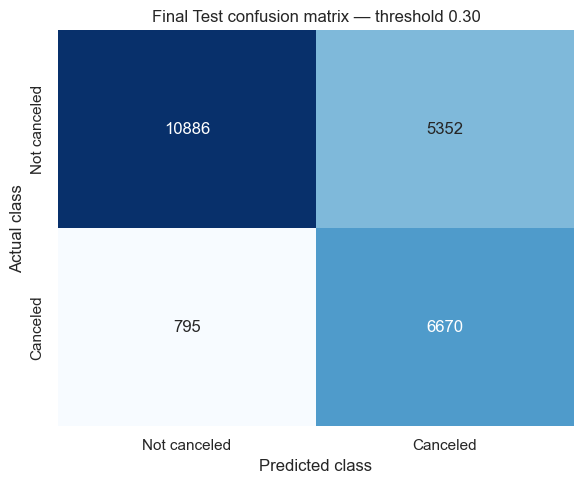

,sklearn,from_confusion_matrix,Difference
Accuracy,0.740666,0.740666,0.0
Precision,0.554816,0.554816,0.0
Recall,0.893503,0.893503,0.0
F1-score,0.684559,0.684559,0.0


In [20]:
final_confusion_matrix = confusion_matrix(
    y_final_test,
    final_test_prediction,
)
tn, fp, fn, tp = final_confusion_matrix.ravel()

plt.figure(figsize=(6, 5))
sns.heatmap(
    final_confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Not canceled", "Canceled"],
    yticklabels=["Not canceled", "Canceled"],
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title(f"Final Test confusion matrix — threshold {FINAL_THRESHOLD:.2f}")
plt.tight_layout()
plt.show()

# 混同行列から指標を再計算し、sklearnの結果と一致することを確認する
metrics_from_confusion_matrix = {
    "Accuracy": (tn + tp) / (tn + fp + fn + tp),
    "Precision": tp / (tp + fp),
    "Recall": tp / (tp + fn),
    "F1-score": 2 * tp / (2 * tp + fp + fn),
}
metric_consistency = pd.DataFrame({
    "sklearn": [final_test_metrics[name] for name in metrics_from_confusion_matrix],
    "from_confusion_matrix": list(metrics_from_confusion_matrix.values()),
}, index=metrics_from_confusion_matrix.keys())
metric_consistency["Difference"] = (
    metric_consistency["sklearn"]
    - metric_consistency["from_confusion_matrix"]
)
display(metric_consistency.round(10))

assert np.allclose(metric_consistency["Difference"], 0)


In [21]:
display(Markdown(f"""
### Final Testの結果

- Accuracy：**{final_test_metrics['Accuracy']:.4f}**
- Precision：**{final_test_metrics['Precision']:.4f}**
- Recall：**{final_test_metrics['Recall']:.4f}**
- F1-score：**{final_test_metrics['F1-score']:.4f}**
- ROC-AUC：**{final_test_metrics['ROC-AUC']:.4f}**
- PR-AUC：**{final_test_metrics['PR-AUC']:.4f}**
- 混同行列：TN={tn:,}、FP={fp:,}、FN={fn:,}、TP={tp:,}

Validationで選んだモデルと閾値を変更せずに評価した。Final Testはモデル選択や閾値調整に使用しておらず、混同行列から再計算したAccuracy・Precision・Recall・F1-scoreもsklearnの出力と一致した。
"""))



### Final Testの結果

- Accuracy：**0.7407**
- Precision：**0.5548**
- Recall：**0.8935**
- F1-score：**0.6846**
- ROC-AUC：**0.8622**
- PR-AUC：**0.7362**
- 混同行列：TN=10,886、FP=5,352、FN=795、TP=6,670

Validationで選んだモデルと閾値を変更せずに評価した。Final Testはモデル選択や閾値調整に使用しておらず、混同行列から再計算したAccuracy・Precision・Recall・F1-scoreもsklearnの出力と一致した。


# 9. 分析結果のまとめ・今後の課題


In [22]:
country_before = country_validation_comparison.loc[
    "Random Forest (before country)"
]
country_after = country_validation_comparison.loc[
    "Random Forest (+ country)"
]

display(Markdown(f"""
## 分析結果のまとめ

1. **Random Forestの正則化**  
   Validation ROC-AUCが最も高かった`{selected_candidate}`を採用した。無制限に近いモデルよりTrainとValidationの差が小さく、過学習を抑えられた。

2. **countryの追加**  
   Validation ROC-AUCは **{country_before['ROC-AUC']:.4f} → {country_after['ROC-AUC']:.4f}**、F1-scoreは **{country_before['F1-score']:.4f} → {country_after['F1-score']:.4f}** となった。

3. **agentの分類方法**  
   上位20社モデルのROC-AUCがわずかに高かったが、上位10社モデルとの差は0.001未満だった。上位10社モデルはカテゴリ数が少なくF1-scoreも最も高かったため、最終モデルに採用した。

4. **閾値の選択**  
   ValidationでF1-scoreが最大となった **{FINAL_THRESHOLD:.2f}** を採用した。閾値0.45はPrecisionを重視する場合の候補として残したが、最終評価には使用していない。

5. **最終モデル**  
   共通20特徴量＋country＋agent、上位17か国、上位10代理店、正則化済みRandom Forest、閾値{FINAL_THRESHOLD:.2f}の組み合わせで統一した。Final TestのROC-AUCは **{final_test_metrics['ROC-AUC']:.4f}**、F1-scoreは **{final_test_metrics['F1-score']:.4f}** だった。

## 今後の課題

- 推定予約日は`到着日 - lead_time`で作っており、実際の予約・更新日時ではない。
- 予約IDがないため完全一致行を削除せず、重複グループが分割をまたがないことだけを確認した。実データでは予約ID単位の分割が望ましい。
- 閾値0.30はF1-scoreを基準に選んだ。実運用では見逃しコストと誤検知への対応コストを金額で整理し、Validation上で目的に合う基準を事前に定める必要がある。
- 時期による性能低下や確率のずれを確認するため、将来データでROC-AUC、PR-AUC、Precision、Recall、確率校正を継続的に監視する必要がある。
- データはリポジトリの`data/`から相対パスで読み込む。CSV自体はGit管理対象外とし、READMEの取得手順に従って配置する。
"""))



## 分析結果のまとめ

1. **Random Forestの正則化**  
   Validation ROC-AUCが最も高かった`depth18_leaf4`を採用した。無制限に近いモデルよりTrainとValidationの差が小さく、過学習を抑えられた。

2. **countryの追加**  
   Validation ROC-AUCは **0.7930 → 0.8600**、F1-scoreは **0.6098 → 0.6303** となった。

3. **agentの分類方法**  
   上位20社モデルのROC-AUCがわずかに高かったが、上位10社モデルとの差は0.001未満だった。上位10社モデルはカテゴリ数が少なくF1-scoreも最も高かったため、最終モデルに採用した。

4. **閾値の選択**  
   ValidationでF1-scoreが最大となった **0.30** を採用した。閾値0.45はPrecisionを重視する場合の候補として残したが、最終評価には使用していない。

5. **最終モデル**  
   共通20特徴量＋country＋agent、上位17か国、上位10代理店、正則化済みRandom Forest、閾値0.30の組み合わせで統一した。Final TestのROC-AUCは **0.8622**、F1-scoreは **0.6846** だった。

## 今後の課題

- 推定予約日は`到着日 - lead_time`で作っており、実際の予約・更新日時ではない。
- 予約IDがないため完全一致行を削除せず、重複グループが分割をまたがないことだけを確認した。実データでは予約ID単位の分割が望ましい。
- 閾値0.30はF1-scoreを基準に選んだ。実運用では見逃しコストと誤検知への対応コストを金額で整理し、Validation上で目的に合う基準を事前に定める必要がある。
- 時期による性能低下や確率のずれを確認するため、将来データでROC-AUC、PR-AUC、Precision、Recall、確率校正を継続的に監視する必要がある。
- データはリポジトリの`data/`から相対パスで読み込む。CSV自体はGit管理対象外とし、READMEの取得手順に従って配置する。
